# Chapitre 1 - Exercices 1.7 à 1.10

Ce notebook traite les derniers exercices du chapitre 1, centrés sur les files
d'attente, la fiabilité et la scalabilité :

- **1.7** : blocage en tête de file, séparer ou prioriser les requêtes lentes
  (mini-lab) ;
- **1.8** : pannes de disques et durabilité des données répliquées (calcul) ;
- **1.9** : disponibilité d'une chaîne de services, budget d'indisponibilité et mises
  à jour progressives (calcul et simulation) ;
- **1.10** : ajuster la loi universelle de scalabilité et choisir une architecture
  (mini-lab et raisonnement).

In [1]:
import heapq
import math
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import requirements as rq
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## Exercice 1.7 : blocage en tête de file, séparer ou prioriser les requêtes lentes

**Énoncé.** Un service dispose de 2 serveurs. 98 % des requêtes sont rapides (service
exponentiel de moyenne 2 ms), 2 % sont lentes (exponentiel de moyenne 200 ms, un rapport
mensuel par exemple). Les arrivées sont poissonniennes et la charge occupe les serveurs à
70 % en moyenne. On compare trois organisations :

- **A** : une file commune FIFO pour les deux serveurs ;
- **B** : un serveur dédié aux requêtes rapides, l'autre aux lentes ;
- **C** : une file commune avec **priorité** (non préemptive) aux requêtes rapides.

1. Calculer le temps de service moyen, le débit d'arrivée, puis l'occupation de chaque
   serveur dans l'organisation B. Que prévoir ?
2. Simuler les trois organisations et comparer p50 et p99 pour chaque classe de requêtes.
3. Conclure : quelle organisation choisir, et à quelle condition ?

**Rappels.** Blocage en tête de file, formule de Pollaczek-Khinchine, mutualisation des
serveurs (cours 3, sections 3 et 4 ; section *Describing Performance*).

**Solution.**

*1.* $\mathbb{E}[S] = 0{,}98 \times 2 + 0{,}02 \times 200 = 5{,}96$ ms. Pour 70 %
d'occupation de 2 serveurs : $\lambda = 0{,}7 \times 2 / 0{,}00596 \approx 235$
requêtes/s. Dans B, le serveur rapide reçoit $0{,}98\lambda$ requêtes de 2 ms : occupation
$\approx 46\,\%$ ; le serveur lent reçoit $0{,}02\lambda$ requêtes de 200 ms : occupation
$\approx 94\,\%$. On prévoit des requêtes rapides excellentes mais des requêtes lentes
**catastrophiques** (facteur $1/(1-\rho) \approx 17$) : la séparation statique déséquilibre
la charge.

*2.* Simulation ci-dessous (petit simulateur à événements pour la priorité).

*3.* Aucune organisation n'est parfaite. B protège au mieux les rapides mais sacrifie les
lentes ; il n'est acceptable que si l'on dimensionne séparément (et généreusement) le
pool des lentes. La priorité (C) est un compromis : les rapides n'attendent plus derrière
une **file** de lentes, seulement derrière les lentes déjà en cours de service, et les
lentes gardent l'accès aux deux serveurs. Elle suppose de **savoir** classer une requête
à son arrivée.

λ = 235 req/s ; occupation B : rapides 46%, lentes 94%


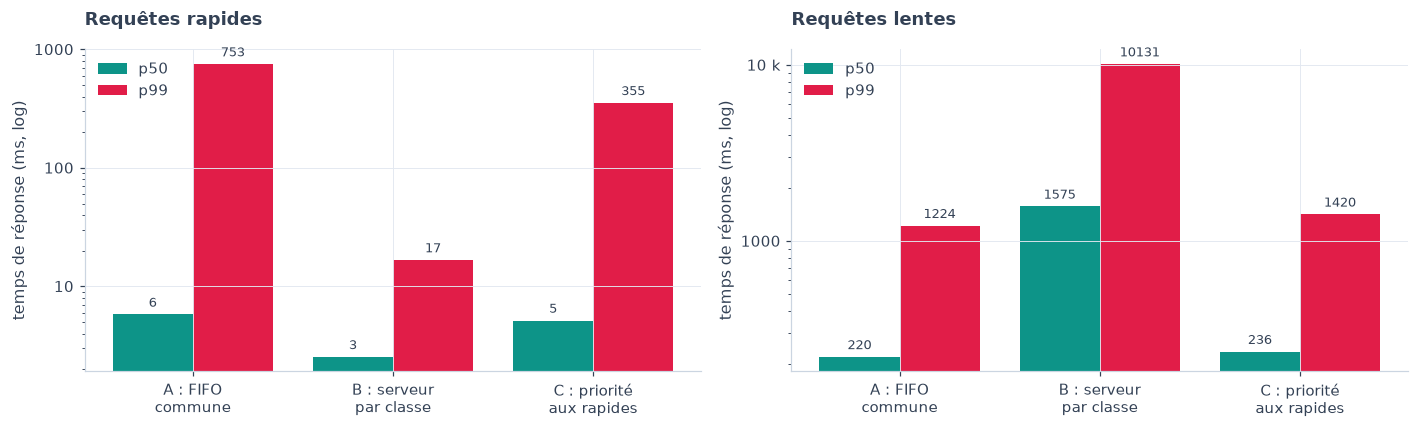

p50              p99        
classe                                  lentes rapides   lentes rapides
organisation                                                           
A : file commune FIFO                    220.0     6.0   1224.0   753.0
B : un serveur par classe               1575.0     3.0  10131.0    17.0
C : file commune, priorité aux rapides   236.0     5.0   1420.0   355.0

In [2]:
def simule_priorite(arr, svc, classe, c=2):
    """File à c serveurs, priorité non préemptive à la classe 0. Renvoie les fins de service."""
    n = arr.size
    fin = np.empty(n)
    files = (deque(), deque())
    libres = c
    evts = [(arr[i], 1, i) for i in range(n)]          # (instant, type 1 = arrivée / 0 = fin, requête)
    heapq.heapify(evts)
    while evts:
        t, typ, i = heapq.heappop(evts)
        if typ == 1:
            files[classe[i]].append(i)
        else:
            libres += 1
        while libres and (files[0] or files[1]):
            j = files[0].popleft() if files[0] else files[1].popleft()
            libres -= 1
            fin[j] = t + svc[j]
            heapq.heappush(evts, (fin[j], 0, j))
    return fin

n = 200_000
lente = rng.random(n) < 0.02
svc = np.where(lente, rng.exponential(0.200, n), rng.exponential(0.002, n))
lam = 0.7 * 2 / (0.98 * 0.002 + 0.02 * 0.200)
arr = rq.poisson_arrivals(lam, n, seed=8)
classe = lente.astype(int)
res = {}
_, fin_A = rq.simulate_fifo(arr, svc, c=2)
res["A : file commune FIFO"] = fin_A - arr
fin_B = np.empty(n)
for cl in (0, 1):
    m = classe == cl
    fin_B[m] = rq.simulate_fifo(arr[m], svc[m])[1]
res["B : un serveur par classe"] = fin_B - arr
res["C : file commune, priorité aux rapides"] = simule_priorite(arr, svc, classe) - arr
rows = []
for nom, r in res.items():
    for cl, lab in [(0, "rapides"), (1, "lentes")]:
        v = r[classe == cl][n // 10:] * 1e3 if cl == 0 else r[classe == cl] * 1e3
        rows.append(dict(organisation=nom, classe=lab, p50=np.percentile(v, 50), p99=np.percentile(v, 99)))
T = pd.DataFrame(rows)
print(f"λ = {lam:.0f} req/s ; occupation B : rapides {lam * 0.98 * 0.002:.0%}, lentes {lam * 0.02 * 0.2:.0%}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, lab in zip(axes, ["rapides", "lentes"]):
    sub = T[T.classe == lab]
    x_ = np.arange(len(sub))
    ax.bar(x_ - 0.2, sub.p50, width=0.4, color=TEAL, label="p50")
    ax.bar(x_ + 0.2, sub.p99, width=0.4, color=ROSE, label="p99")
    annotate_bars(ax, "{:.0f}", fontsize=8.5)
    ax.set_xticks(x_); ax.set_xticklabels(["A : FIFO\ncommune", "B : serveur\npar classe", "C : priorité\naux rapides"])
    ax.set_yscale("log"); rq.plain_log_axis(ax, "y")
    ax.set_ylabel("temps de réponse (ms, log)")
    ax.set_title(f"Requêtes {lab}")
    ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
T.pivot(index="organisation", columns="classe", values=["p50", "p99"]).round(0)

Comme prévu, B rend les requêtes rapides excellentes (p99 de 17 ms) mais fait exploser le
temps des lentes (le serveur dédié est occupé à 94 %, p99 de 10 s). La file commune FIFO
(A) inflige aux rapides un p99 de 750 ms : le blocage en tête de file. La priorité (C)
divise ce p99 par deux tout en gardant les lentes proches de A ; mais elle reste loin de
B pour les rapides, car les lentes représentent près d'un serveur de charge à elles
seules : il arrive souvent que **les deux** serveurs soient occupés par des lentes, et une
requête rapide doit alors attendre la fin de l'une d'elles. Pour faire mieux, il faudrait
réserver de la capacité aux rapides (un troisième serveur, ou la préemption).

> **À retenir.** Isoler les requêtes lentes protège les rapides, mais une séparation
> statique déséquilibre la charge. Une file commune avec priorité garde la mutualisation
> et réduit le blocage en tête de file sans le supprimer : tant que des requêtes lentes
> occupent tous les serveurs, les rapides attendent.

## Exercice 1.8 : pannes de disques et durabilité

**Énoncé.** Un service de stockage utilise 50 000 disques d'AFR 2 %. Les données sont
découpées en 1 million de groupes, chacun répliqué sur $r$ disques distincts.

1. Quel est le MTTF d'un disque ? Combien de pannes de disque par jour en moyenne ?
   Quelle est la probabilité de n'en avoir aucune un jour donné ?
2. Calculer le MTTDL d'un groupe pour $r = 2$ et $r = 3$, avec une reconstruction de 12 h
   puis de 48 h. En déduire la probabilité de perdre au moins un groupe en un an.
3. Un défaut de lot de fabrication peut détruire d'un coup toutes les copies d'un groupe
   dont les disques viennent du même lot ; on estime ce risque à $10^{-6}$ par groupe et
   par an. Que devient la probabilité de perte pour $r = 3$ ? Que recommander ?

**Rappels.** $\text{MTTF} = -8760/\ln(1 - \text{AFR})$ ; nombre de pannes ≈ Poisson ;
$\text{MTTDL} \approx 1/(r\lambda^r T^{r-1})$ ; pannes corrélées (cours 4, sections 3 et 4 ;
section *Hardware Faults*).

**Solution.**

*1.* $\text{MTTF} = -8760/\ln(0{,}98) \approx 433\,600$ h ≈ 49,5 ans. Pannes par jour :
$50\,000 \times (-\ln 0{,}98)/365 \approx 2{,}77$. Probabilité d'une journée sans panne :
$e^{-2{,}77} \approx 6\,\%$. Les pannes sont quotidiennes.

*2.* Avec $\lambda = 1/\text{MTTF} \approx 2{,}31 \cdot 10^{-6}$ par heure :
pour $r = 2$, $T = 12$ h : $\text{MTTDL} = 1/(2\lambda^2 T) \approx 7{,}8 \cdot 10^{9}$ h ;
le taux de perte pour $10^6$ groupes vaut $10^6 \times 8760/\text{MTTDL} \approx 1{,}1$ par an,
soit une probabilité de perte annuelle d'environ 67 %. Pour $r = 3$, $T = 12$ h : le
MTTDL est multiplié par $2/(3\lambda T) \approx 24\,000$ : probabilité ≈ $5 \cdot 10^{-5}$.
Passer à 48 h de reconstruction multiplie le risque par 4 ($r = 2$) ou 16 ($r = 3$) :
le temps de reconstruction compte autant que le nombre de copies (tableau ci-dessous).

*3.* Le choc de lot ajoute $10^6 \times 10^{-6} = 1$ perte attendue par an : la
probabilité annuelle remonte à environ 63 %, comme si l'on n'avait que deux copies. Il
faut donc **diversifier** : copies sur des disques de lots, de modèles, de racks et de
centres de données différents, pour que les pannes redeviennent indépendantes.

In [3]:
afr, n_disques, groupes = 0.02, 50_000, 1_000_000
mttf = rq.mttf_hours_from_afr(afr)
par_jour = rq.expected_failures(n_disques, afr, 1)
print(f"MTTF = {mttf:,.0f} h ({mttf / 8760:.1f} ans) ; pannes/jour = {par_jour:.2f} ; "
      f"P(journée sans panne) = {math.exp(-par_jour):.1%}".replace(",", " "))
rows = []
for r in (2, 3):
    for T in (12, 48):
        m = rq.mttdl_hours(afr, r, T)
        p = rq.p_loss_per_year(afr, r, T, groupes)
        p_choc = 1 - (1 - p) * math.exp(-1e-6 * groupes)
        rows.append(dict(copies=r, reconstruction_h=T, MTTDL_ans=f"{m / 8760:.2e}", P_perte_an=f"{p:.2e}",
                         P_perte_an_avec_choc=f"{p_choc:.2f}"))
pd.DataFrame(rows)

MTTF = 433 605 h (49.5 ans) ; pannes/jour = 2.77 ; P(journée sans panne) = 6.3%


,copies,reconstruction_h,MTTDL_ans,P_perte_an,P_perte_an_avec_choc
0,2,12,8.94e+05,6.73e-01,0.88
1,2,48,2.24e+05,9.89e-01,1.00
2,3,12,2.15e+10,4.64e-05,0.63
3,3,48,1.35e+09,7.42e-04,0.63


**Vérification par simulation** (paramètres exagérés pour observer des pertes : AFR 30 %,
20 000 groupes sur 10 ans), en faisant varier le temps de reconstruction, et comparaison
avec la formule.

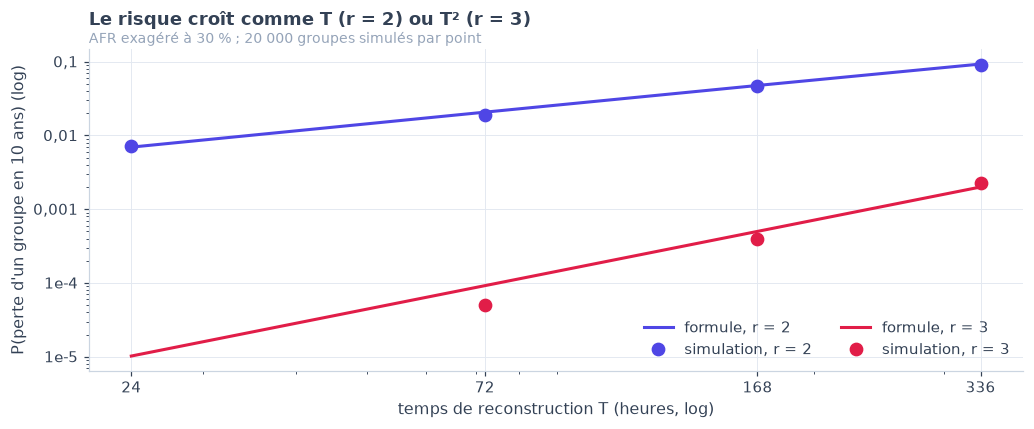

In [4]:
Ts = [24, 72, 168, 336]
fig, ax = plt.subplots(figsize=(9.5, 4))
for r, c in [(2, INDIGO), (3, ROSE)]:
    sim = [np.isfinite(rq.simulate_data_loss(r, 0.30, T, 10, 20_000, seed=r * 100 + T)).mean() for T in Ts]
    th = [1 - math.exp(-10 * 8760 / rq.mttdl_hours(0.30, r, T)) for T in Ts]
    ax.plot(Ts, th, "-", color=c, label=f"formule, r = {r}")
    ax.plot(Ts, sim, "o", color=c, ms=8, label=f"simulation, r = {r}")
ax.set_xscale("log"); ax.set_yscale("log"); rq.plain_log_axis(ax)
ax.set_xticks(Ts); ax.set_xticklabels([str(t) for t in Ts])
ax.set_xlabel("temps de reconstruction T (heures, log)"); ax.set_ylabel("P(perte d'un groupe en 10 ans) (log)")
ax.set_title("Le risque croît comme T (r = 2) ou T² (r = 3)")
subtitle(ax, "AFR exagéré à 30 % ; 20 000 groupes simulés par point")
ax.legend(loc="lower right", ncol=2)
plt.tight_layout(); plt.show()

Les pentes en log-log valent 1 pour $r = 2$ et 2 pour $r = 3$, comme le prédit
$T^{r-1}$ ; la formule surestime légèrement le risque quand $\lambda T$ n'est plus
négligeable. Accélérer la reconstruction (par exemple en la répartissant sur de nombreux
disques au lieu d'un seul disque de remplacement) est un levier aussi puissant qu'ajouter
une copie.

> **À retenir.** À grande échelle, les pannes de disques sont quotidiennes. La durabilité
> dépend du nombre de copies **et** du temps de reconstruction ($T^{r-1}$), et elle est
> plafonnée par les pannes corrélées : on diversifie les domaines de panne.

## Exercice 1.9 : disponibilité d'une chaîne de services et budget d'indisponibilité

**Énoncé.**

1. Une requête traverse 10 services en série, chacun disponible à 99,9 %. Quelle est la
   disponibilité de bout en bout ? Quelle disponibilité faut-il à chaque service pour
   atteindre 99,9 % de bout en bout ?
2. Chaque service est maintenant déployé en 2 répliques indépendantes (une seule suffit).
   Que devient la disponibilité de bout en bout ?
3. L'objectif est 99,9 % par mois de 30 jours. Quel est le budget d'indisponibilité ? Un
   service à un seul nœud doit être redémarré 15 minutes par mois pour appliquer des
   correctifs : quelle part du budget cela consomme-t-il ? Et avec 3 nœuds mis à jour un
   par un ? Quelle contrainte de capacité cela impose-t-il ?
4. Vérifier la question 1 par une simulation de l'état (en marche / en panne) de chaque
   service au cours d'une année.

**Rappels.** Série : produit des disponibilités ; redondance : $1 - \prod(1-a_i)$ ;
budget d'indisponibilité ; mises à jour progressives (cours 2, section 6 et cours 4,
sections 1 et 4 ; section *Hardware Faults*).

**Solution.**

*1.* $0{,}999^{10} \approx 0{,}990$ : **99,0 %**, soit 7,2 heures de panne par mois au lieu
de 43 minutes. Pour 99,9 % de bout en bout : $a = 0{,}999^{1/10} \approx 0{,}9999$, soit
**99,99 %** par service (un « neuf » de plus).

*2.* Chaque service redondant : $1 - 0{,}001^2 = 0{,}999999$ ; de bout en bout :
$0{,}999999^{10} \approx 0{,}99999$ (cinq neuf), si les pannes des répliques sont
indépendantes.

*3.* Budget : $0{,}001 \times 30 \times 24 \times 60 = 43{,}2$ minutes par mois. Un
redémarrage mensuel de 15 minutes en consomme **35 %**, avant toute panne imprévue. Avec
3 nœuds mis à jour un par un, l'indisponibilité planifiée tombe à zéro, mais pendant
chaque redémarrage les 2 nœuds restants absorbent toute la charge : il faut que
l'occupation normale reste sous $2/3 \approx 67\,\%$ (et nettement moins pour garder un
temps de réponse correct, cours 3).

*4.* Simulation : chaque service alterne des périodes de marche (exponentielles de
moyenne 999 h) et de panne (exponentielles de moyenne 1 h), ce qui donne 99,9 % de
disponibilité ; la chaîne marche quand les 10 services marchent.

chaîne de 10 à 99,9 % : 0.9900 ; par service pour 99,9 % : 0.999900
avec 2 répliques : 0.999990
budget mensuel : 43.2 min ; redémarrage de 15 min : 35% du budget


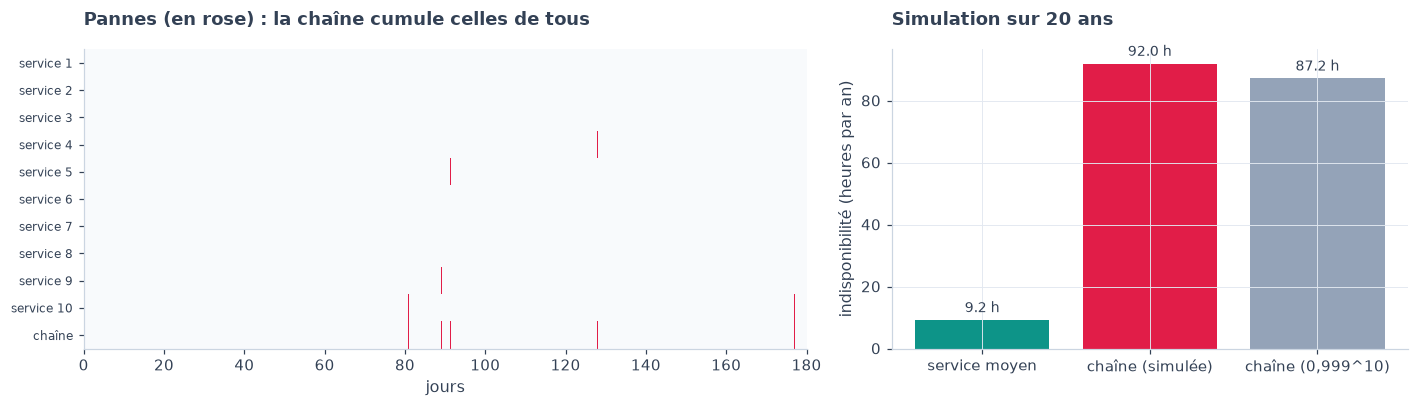

In [5]:
print(f"chaîne de 10 à 99,9 % : {0.999 ** 10:.4f} ; par service pour 99,9 % : {0.999 ** 0.1:.6f}")
print(f"avec 2 répliques : {rq.series_availability(*[rq.parallel_availability(0.999, 0.999)] * 10):.6f}")
budget = rq.downtime_minutes(0.999, 30)
print(f"budget mensuel : {budget:.1f} min ; redémarrage de 15 min : {15 / budget:.0%} du budget")

def etats(mtbf, mttr, horizon, pas, g):
    """Série temporelle 0/1 (1 = en marche) échantillonnée tous les `pas` heures."""
    t, up, bascules = 0.0, True, []
    while t < horizon:
        t += g.exponential(mtbf if up else mttr)
        bascules.append(t)
        up = not up
    grille = np.arange(0, horizon, pas)
    return (np.searchsorted(np.array(bascules), grille, side="right") % 2 == 0).astype(int)

g = np.random.default_rng(1)
horizon, pas = 8760 * 20, 0.1
S = np.array([etats(999, 1, horizon, pas, g) for _ in range(10)])
chaine = S.min(axis=0)
dispo = S.mean(axis=1)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1.4, 1]))
fen = slice(0, int(24 * 30 / pas) * 6)                      # 6 premiers mois
im = np.vstack([S[:, fen], chaine[fen]])
from matplotlib.colors import ListedColormap
ax.imshow(1 - im, aspect="auto", cmap=ListedColormap(["#F8FAFC", ROSE]), vmin=0, vmax=1, interpolation="nearest",
          extent=[0, im.shape[1] * pas / 24, 11, 0])
ax.set_yticks(np.arange(11) + 0.5); ax.set_yticklabels([f"service {i + 1}" for i in range(10)] + ["chaîne"], fontsize=8)
ax.set_xlabel("jours"); ax.grid(False)
ax.set_title("Pannes (en rose) : la chaîne cumule celles de tous")
ax2.bar(["service moyen", "chaîne (simulée)", "chaîne (0,999^10)"],
        [(1 - dispo.mean()) * 8760, (1 - chaine.mean()) * 8760, (1 - 0.999 ** 10) * 8760], color=[TEAL, ROSE, GRAY])
annotate_bars(ax2, "{:.1f} h")
ax2.set_ylabel("indisponibilité (heures par an)"); ax2.set_title("Simulation sur 20 ans")
plt.tight_layout(); plt.show()

La simulation retrouve environ 90 heures d'indisponibilité par an pour la chaîne (87 selon
la formule), contre 9 pour un service seul : les pannes indépendantes s'additionnent presque
exactement (on a rarement deux services en panne en même temps). C'est l'argument
quantitatif contre les longues chaînes d'appels synchrones.

> **À retenir.** En série, les indisponibilités s'additionnent : dix services à 99,9 %
> font un système à 99 %. La redondance (si les pannes sont indépendantes) et les mises à
> jour progressives (si la capacité restante suffit) protègent le budget
> d'indisponibilité.